# Step 4 — Customer-Level EDA

**Learning progress**
| Step | Topic | Status |
|------|-------|--------|
| 0 | Problem formulation | COMPLETE |
| 1 | Transaction-level exploration | COMPLETE |
| 2 | Transaction data cleaning | COMPLETE |
| 3 | Clean-data validation | COMPLETE |
| **4** | **Customer-level EDA** | **this notebook** |

**Scope:** Understand customer behaviour before defining final ML features.  
No model training. No feature matrix saved. No modifications to the cleaned dataset.

**Input:** `data/interim/transactions_cleaned.csv`  
**Prediction cutoff:** `2011-09-01`

---
## Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path('..').resolve()
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import src as _src_pkg
if 'ecommerce_customer_value_prediction' not in sys.modules:
    sys.modules['ecommerce_customer_value_prediction'] = _src_pkg

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.4f}'.format)

CLEANED_CSV  = PROJECT_ROOT / 'data' / 'interim' / 'transactions_cleaned.csv'
CUTOFF       = pd.Timestamp('2011-09-01')
PRED_DATE    = CUTOFF  # alias used in comments

df = pd.read_csv(CLEANED_CSV, parse_dates=['InvoiceDate'])
df['Customer ID'] = df['Customer ID'].astype('Int64')
df['Invoice']     = df['Invoice'].astype(str)
df['StockCode']   = df['StockCode'].astype(str)

print('Cleaned dataset loaded.')
print(f'  Shape : {df.shape[0]:,} rows x {df.shape[1]} cols')
print(f'  Cutoff: {CUTOFF.date()}')


Cleaned dataset loaded.
  Shape : 84,955 rows x 9 cols
  Cutoff: 2011-09-01


---
## Part 1 — From Transactions to Customers

### Transaction-level analysis vs. customer-level analysis

| Dimension | Transaction-level | Customer-level |
|-----------|------------------|----------------|
| **Unit of analysis** | One line item | One customer |
| **Rows in dataset** | 84,955 (after cleaning) | ~4,374 |
| **Questions answered** | Which products sell? When are peaks? What is average basket? | Who spends most? Who is likely to return? Who has lapsed? |
| **Used in** | Data cleaning, quality checks, EDA of transactions | Feature engineering, ML model training |
| **Notebook** | 01, 02, 03 | This notebook and beyond |

### Why we must collapse rows

Our cleaned dataset has **many rows per customer** — one for each line item purchased.  
The final ML model needs **exactly one row per customer** containing a numerical summary
of that customer's historical behaviour.

A regression model cannot accept variable-length sequences of transactions as input.
It needs a fixed-width feature vector.

### Conceptual example

```
Transaction-level (raw input)          Customer-level (ML input)
──────────────────────────────         ──────────────────────────────────────
Customer A | Invoice 1 | 2010-01-05    Customer A
Customer A | Invoice 1 | 2010-01-05    → recency_days   = 239
Customer A | Invoice 2 | 2010-03-12    → frequency      = 3  (unique invoices)
Customer A | Invoice 2 | 2010-03-12    → monetary       = £284.50
Customer A | Invoice 3 | 2010-09-15    → avg_basket     = £94.83
Customer A | Invoice 3 | 2010-09-15    → unique_products = 5
                                        → tenure_days   = 253
```

This notebook explores each of those summary statistics **for EDA purposes only**.
The final feature matrix is built in Step 5.

In [2]:
# Confirm: multiple rows per customer
rows_per_customer = df.groupby('Customer ID').size()
print('Rows per customer (sample):')
print(rows_per_customer.describe().to_string())
print(f'\nCustomers with exactly 1 row : {(rows_per_customer == 1).sum():,}')
print(f'Customers with 10+ rows      : {(rows_per_customer >= 10).sum():,}')
print(f'Max rows for one customer    : {rows_per_customer.max():,}')


Rows per customer (sample):
count   4,846.0000
mean       17.5310
std        46.9752
min         1.0000
25%         3.0000
50%         7.0000
75%        18.0000
max     1,690.0000

Customers with exactly 1 row : 620
Customers with 10+ rows      : 1,970
Max rows for one customer    : 1,690


---
## Part 2 — Define the Historical Analysis Window

### Why we use only pre-cutoff data for feature analysis

In a real deployment this model would be trained on data up to some date
and then used to predict **future** revenue. The cutoff simulates that boundary.

If we used post-cutoff transactions to compute 'historical' statistics,
we would be leaking future information into the features.
The model would appear to predict well in validation but fail in production
where the future data does not exist yet.

**Rule:** Everything labelled `historical_*` in this notebook uses
`InvoiceDate < 2011-09-01` only.

In [3]:
historical_df = df[df['InvoiceDate'] < CUTOFF].copy()
future_df     = df[df['InvoiceDate'] >= CUTOFF].copy()

print('Historical window (features):')
print(f'  Transactions : {len(historical_df):,}')
print(f'  Customers    : {historical_df["Customer ID"].nunique():,}')
print(f'  Invoices     : {historical_df["Invoice"].nunique():,}')
print(f'  Revenue      : £{historical_df["line_total"].sum():,.2f}')
print(f'  Date range   : {historical_df["InvoiceDate"].min().date()} '
      f'to {historical_df["InvoiceDate"].max().date()}')

print()
print('Future window (target measurement only):')
print(f'  Transactions : {len(future_df):,}')
print(f'  Customers    : {future_df["Customer ID"].nunique():,}')
print(f'  Invoices     : {future_df["Invoice"].nunique():,}')
print(f'  Revenue      : £{future_df["line_total"].sum():,.2f}')
print(f'  Date range   : {future_df["InvoiceDate"].min().date()} '
      f'to {future_df["InvoiceDate"].max().date()}')


Historical window (features):
  Transactions : 73,306
  Customers    : 4,374
  Invoices     : 19,171


  Revenue      : £1,758,649.54
  Date range   : 2009-12-01 to 2011-08-31

Future window (target measurement only):
  Transactions : 11,649
  Customers    : 2,016
  Invoices     : 3,715
  Revenue      : £225,288.61
  Date range   : 2011-09-01 to 2011-12-09


---
## Part 3 — Customer Purchase Frequency

**Definition (for EDA):** number of unique invoices per customer in the historical window.

### Why unique invoices, not raw line count?

A single shopping trip (one invoice) can contain many line items.
If a customer buys 20 different products in one visit, that is still
**one purchase event**. Using raw line count would confuse product variety
with purchase frequency.

| Metric | Counts | Meaning |
|--------|--------|---------|
| `df.groupby(...).size()` | Line items | How many products across all trips |
| `df.groupby(...).Invoice.nunique()` | Unique invoices | How many shopping trips |

### Why right skew is expected

Most customers are occasional shoppers (1–5 trips). A small number of
customers — often wholesale buyers or business accounts — place orders
many times per month. This creates a long right tail.

**High-frequency customers** may represent:
- Regular wholesale buyers (legitimate)
- Business accounts purchasing for resale (legitimate)
- Data anomalies worth investigating individually

We do not automatically remove them at this stage.

In [4]:
freq = (
    historical_df.groupby('Customer ID')['Invoice']
    .nunique()
    .rename('frequency')
)

pcts = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
print('Purchase Frequency (unique invoices) — historical window')
print(f'  Min    : {freq.min()}')
for p in pcts:
    print(f'  {int(p*100):>3}th % : {freq.quantile(p):.1f}')
print(f'  Mean   : {freq.mean():.2f}')
print(f'  Max    : {freq.max()}')
print(f'  Skew   : {freq.skew():.2f}')

print()
print(f'Customers with frequency = 1 : {(freq == 1).sum():,} ({(freq==1).mean()*100:.1f}%)')
print(f'Customers with frequency > 50: {(freq > 50).sum():,}')


Purchase Frequency (unique invoices) — historical window
  Min    : 1
   25th % : 1.0
   50th % : 2.0
   75th % : 5.0
   90th % : 10.0
   95th % : 14.0
   99th % : 30.0
  Mean   : 4.38
  Max    : 194
  Skew   : 10.85

Customers with frequency = 1 : 1,624 (37.1%)
Customers with frequency > 50: 16


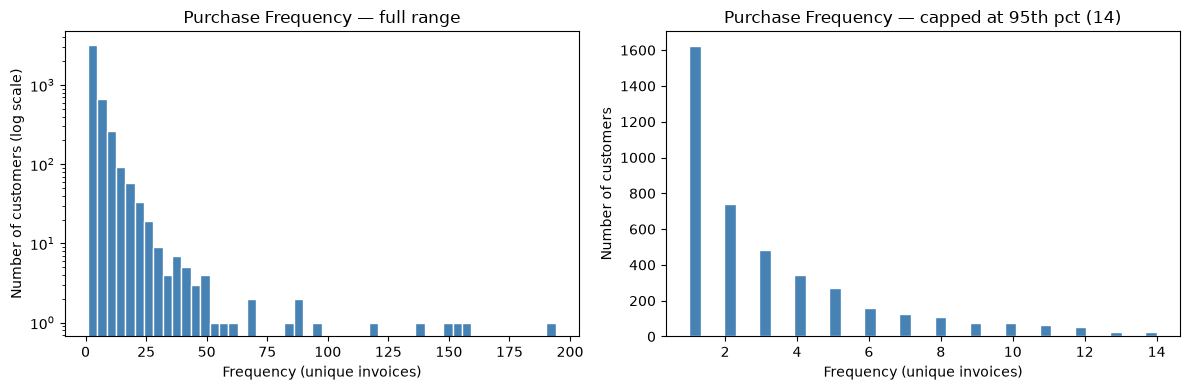

Top 10 highest-frequency customers:
             frequency
Customer ID           
14911              194
17841              159
14606              152
15311              149
12748              137
17850              118
14527               95
13694               89
13089               87
14156               83


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: full distribution (log y-axis to show the tail)
axes[0].hist(freq, bins=50, color='steelblue', edgecolor='white')
axes[0].set_yscale('log')
axes[0].set_xlabel('Frequency (unique invoices)')
axes[0].set_ylabel('Number of customers (log scale)')
axes[0].set_title('Purchase Frequency — full range')

# Right: capped at 95th percentile to show the bulk
cap = freq.quantile(0.95)
axes[1].hist(freq[freq <= cap], bins=40, color='steelblue', edgecolor='white')
axes[1].set_xlabel('Frequency (unique invoices)')
axes[1].set_ylabel('Number of customers')
axes[1].set_title(f'Purchase Frequency — capped at 95th pct ({cap:.0f})')

plt.tight_layout()
plt.show()

# Top 10 most frequent customers
print('Top 10 highest-frequency customers:')
print(freq.nlargest(10).to_frame().to_string())


---
## Part 4 — Customer Historical Monetary Value

**Definition (for EDA):** sum of `line_total` per customer in the historical window.

### Why mean >> median indicates right skew

The mean is sensitive to extreme values; the median is not.
If a handful of customers spend £20,000+ while most spend £200,
the mean is pulled far right of the median.

This is typical in retail: the Pareto principle (roughly 80/20) often applies —
a small fraction of customers generate the majority of revenue.

### High-value customer vs. data error

| Scenario | What it looks like | Correct response |
|----------|--------------------|-----------------|
| Wholesale buyer | Very high revenue, high frequency, UK or specific country | Keep — valid signal |
| Legitimate corporate account | Consistent orders, real StockCodes | Keep |
| Duplicate transactions not caught | Revenue exactly 2x peer group | Investigate |
| Price data entry error | Single line with £999,999 | Investigate |

We investigate but do not remove at this stage.

In [6]:
monetary = (
    historical_df.groupby('Customer ID')['line_total']
    .sum()
    .rename('monetary')
)

pcts = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
print('Historical Monetary Value (£) — per customer')
print(f'  Min    : £{monetary.min():>12,.2f}')
for p in pcts:
    print(f'  {int(p*100):>3}th % : £{monetary.quantile(p):>12,.2f}')
print(f'  Mean   : £{monetary.mean():>12,.2f}')
print(f'  Max    : £{monetary.max():>12,.2f}')
print(f'  Skew   : {monetary.skew():.2f}')
print()
print(f'  Mean/Median ratio: {monetary.mean()/monetary.median():.2f}x  (> 1 = right skew)')


Historical Monetary Value (£) — per customer
  Min    : £        0.38
   10th % : £       16.35
   25th % : £       36.77
   50th % : £       98.18
   75th % : £      273.87
   90th % : £      699.40
   95th % : £    1,147.42
   99th % : £    4,590.65
  Mean   : £      402.07
  Max    : £   59,853.80
  Skew   : 18.19

  Mean/Median ratio: 4.10x  (> 1 = right skew)


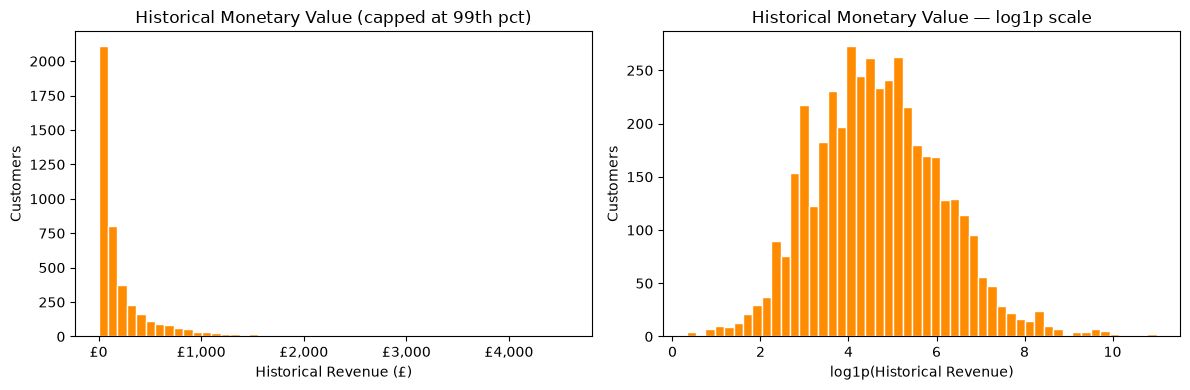

Top 10 highest-spending customers (historical):
 Customer ID  historical_revenue  frequency
       13694         59,853.8000         89
       18102         49,316.5500         35
       14646         43,161.1800         56
       15769         33,226.3200         30
       14156         21,182.5400         83
       14911         21,152.5400        194
       17511         20,045.6400         42
       15311         19,769.1000        149
       13798         18,847.1800         67
       16029         18,447.8000         47


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: raw monetary (capped at 99th pct)
cap99 = monetary.quantile(0.99)
axes[0].hist(monetary[monetary <= cap99], bins=50, color='darkorange', edgecolor='white')
axes[0].set_xlabel('Historical Revenue (£)')
axes[0].set_ylabel('Customers')
axes[0].set_title('Historical Monetary Value (capped at 99th pct)')
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'£{x:,.0f}'))

# Right: log1p scale
import numpy as np
axes[1].hist(np.log1p(monetary), bins=50, color='darkorange', edgecolor='white')
axes[1].set_xlabel('log1p(Historical Revenue)')
axes[1].set_ylabel('Customers')
axes[1].set_title('Historical Monetary Value — log1p scale')

plt.tight_layout()
plt.show()

print('Top 10 highest-spending customers (historical):')
top10_m = monetary.nlargest(10).reset_index()
top10_m.columns = ['Customer ID', 'historical_revenue']
top10_f = freq.reset_index()
top10_f.columns = ['Customer ID', 'frequency']
print(top10_m.merge(top10_f, on='Customer ID').to_string(index=False))


---
## Part 5 — Recency

**Definition (for EDA):**
```
recency = prediction_date − customer's most recent historical purchase date
```

**Interpretation:**
- **Low recency** (e.g., 5 days) → purchased very recently before the cutoff
- **High recency** (e.g., 400 days) → has not purchased for a long time

Recency is intuitively predictive: a customer who bought yesterday is more likely
to buy again soon than one who hasn't been seen in a year.
This is the 'R' in the classic RFM framework.

### Why recency may be useful for predicting future spending

Customers who purchased recently:
- Are still engaged with the retailer
- Are likely within an active purchasing cycle
- May be triggered by a follow-up marketing campaign

Customers who haven't purchased for a long time:
- May have churned
- May have switched to a competitor
- Are less likely to return — so their predicted future revenue should be lower

A linear model can capture this relationship if recency has a roughly linear
relationship with future revenue (we will test this in Part 13).

Recency (days from last purchase to cutoff):
  Min    : 0 days
  25th % : 69.0 days
  Median : 211.0 days
  Mean   : 230.8 days
  75th % : 342.0 days
  95th % : 559.3 days
  Max    : 638 days
  Skew   : 0.49


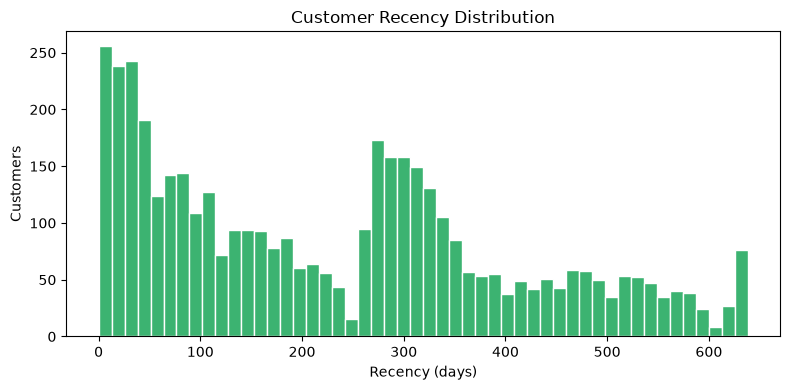

In [8]:
last_purchase = (
    historical_df.groupby('Customer ID')['InvoiceDate']
    .max()
    .rename('last_purchase')
)
recency = (CUTOFF - last_purchase).dt.days.rename('recency_days')

print('Recency (days from last purchase to cutoff):')
print(f'  Min    : {recency.min()} days')
print(f'  25th % : {recency.quantile(0.25):.1f} days')
print(f'  Median : {recency.median():.1f} days')
print(f'  Mean   : {recency.mean():.1f} days')
print(f'  75th % : {recency.quantile(0.75):.1f} days')
print(f'  95th % : {recency.quantile(0.95):.1f} days')
print(f'  Max    : {recency.max()} days')
print(f'  Skew   : {recency.skew():.2f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(recency, bins=50, color='mediumseagreen', edgecolor='white')
ax.set_xlabel('Recency (days)')
ax.set_ylabel('Customers')
ax.set_title('Customer Recency Distribution')
plt.tight_layout()
plt.show()


---
## Part 6 — Customer Tenure

**Definitions:**
```
first_purchase_date = customer's earliest InvoiceDate in historical window
last_purchase_date  = customer's most recent InvoiceDate in historical window
tenure              = last_purchase_date − first_purchase_date  (days)
```

### Edge case: tenure == 0

A customer has `tenure == 0` when ALL their historical purchases occurred
on the **same calendar day**. This can happen when:
- A customer made exactly one purchase (single invoice, or multiple items on one day)
- A customer placed multiple orders on the same day

This is **not a data error** — it is a legitimate behavioural pattern.

The edge case matters because it affects derived features:
```
purchase_rate = frequency / tenure_days
```
If `tenure_days == 0`, this would produce a division by zero.
In Step 5 we will handle this explicitly (e.g., set `purchase_rate = 0` when `tenure == 0`).

We do not decide the final formula here — we just identify the edge case.

In [9]:
first_purchase = (
    historical_df.groupby('Customer ID')['InvoiceDate']
    .min()
    .rename('first_purchase')
)
tenure = (last_purchase - first_purchase).dt.days.rename('tenure_days')

print('Customer Tenure (days):')
print(f'  tenure == 0  : {(tenure == 0).sum():,} customers ({(tenure==0).mean()*100:.1f}%)')
print(f'  tenure == 1  : {(tenure == 1).sum():,} customers')
print(f'  Median       : {tenure.median():.1f} days')
print(f'  Mean         : {tenure.mean():.1f} days')
print(f'  75th %       : {tenure.quantile(0.75):.1f} days')
print(f'  Max          : {tenure.max()} days')

# Show a tenure==0 example
zero_tenure_ids = tenure[tenure == 0].index[:3].tolist()
if zero_tenure_ids:
    cid = zero_tenure_ids[0]
    ex = historical_df[historical_df['Customer ID'] == cid][['Invoice','InvoiceDate','line_total']]
    print(f'\nExample: Customer {cid} (tenure=0) — all purchases on one day:')
    print(ex.to_string(index=False))


Customer Tenure (days):
  tenure == 0  : 1,658 customers (37.9%)
  tenure == 1  : 2 customers
  Median       : 125.0 days
  Mean         : 198.7 days
  75th %       : 372.0 days
  Max          : 637 days

Example: Customer 12350 (tenure=0) — all purchases on one day:
Invoice         InvoiceDate  line_total
 543037 2011-02-02 16:01:00      8.5000
 543037 2011-02-02 16:01:00     10.2000
 543037 2011-02-02 16:01:00     17.7000


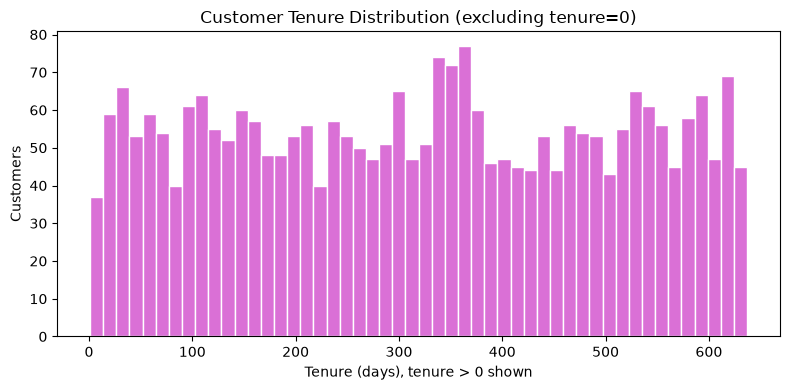

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(tenure[tenure > 0], bins=50, color='orchid', edgecolor='white')
ax.set_xlabel('Tenure (days), tenure > 0 shown')
ax.set_ylabel('Customers')
ax.set_title('Customer Tenure Distribution (excluding tenure=0)')
plt.tight_layout()
plt.show()


---
## Part 7 — Average Order Value

**Definition:**
```
average_order_value = historical_revenue / number_of_unique_invoices
```

### What it represents

AOV measures how much a customer spends **per shopping trip** on average.
It separates two components of monetary value:
- **How often** the customer shops (frequency)
- **How much** they spend each time (AOV)

### High monetary + moderate AOV vs. low frequency + high AOV

| Customer type | Frequency | AOV | Total monetary |
|---------------|-----------|-----|----------------|
| Regular moderate spender | 20 | £50 | £1,000 |
| Occasional big spender | 2 | £500 | £1,000 |

Both have the same total monetary value but very different behaviour.
AOV provides information **beyond** what frequency and monetary value already capture.
However, note that `monetary = frequency × AOV` exactly, so including all three
in a regression creates perfect multicollinearity.
This is a feature-engineering decision to resolve in Step 5.

Average Order Value (£) — per customer:
  Min    : £      0.38
  25th % : £     22.62
  Median : £     40.48
  Mean   : £     68.00
  75th % : £     72.22
  99th % : £    519.01
  Max    : £  5,199.50
  Skew   : 17.42


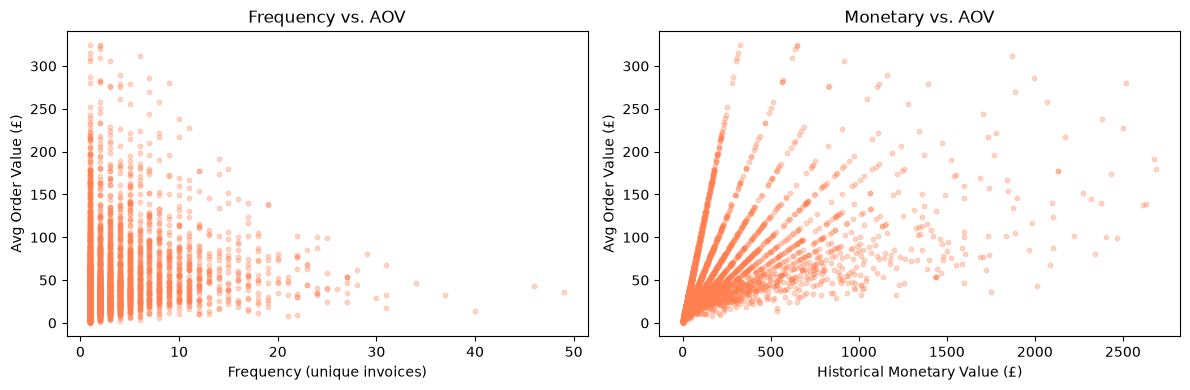

In [11]:
# Invoice-level spend
inv_spend = (
    historical_df.groupby(['Customer ID', 'Invoice'])['line_total']
    .sum()
    .reset_index()
    .rename(columns={'line_total': 'invoice_spend'})
)
aov = (
    inv_spend.groupby('Customer ID')['invoice_spend']
    .mean()
    .rename('avg_order_value')
)

print('Average Order Value (£) — per customer:')
print(f'  Min    : £{aov.min():>10,.2f}')
print(f'  25th % : £{aov.quantile(0.25):>10,.2f}')
print(f'  Median : £{aov.median():>10,.2f}')
print(f'  Mean   : £{aov.mean():>10,.2f}')
print(f'  75th % : £{aov.quantile(0.75):>10,.2f}')
print(f'  99th % : £{aov.quantile(0.99):>10,.2f}')
print(f'  Max    : £{aov.max():>10,.2f}')
print(f'  Skew   : {aov.skew():.2f}')

# Scatter: monetary vs AOV
compare_df = pd.concat([monetary, aov, freq], axis=1).dropna()
compare_df.columns = ['monetary', 'avg_order_value', 'frequency']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Cap for clarity
m_cap = monetary.quantile(0.98)
a_cap = aov.quantile(0.98)
sub = compare_df[(compare_df['monetary'] <= m_cap) & (compare_df['avg_order_value'] <= a_cap)]

axes[0].scatter(sub['frequency'], sub['avg_order_value'], alpha=0.3, s=10, color='coral')
axes[0].set_xlabel('Frequency (unique invoices)')
axes[0].set_ylabel('Avg Order Value (£)')
axes[0].set_title('Frequency vs. AOV')

axes[1].scatter(sub['monetary'], sub['avg_order_value'], alpha=0.3, s=10, color='coral')
axes[1].set_xlabel('Historical Monetary Value (£)')
axes[1].set_ylabel('Avg Order Value (£)')
axes[1].set_title('Monetary vs. AOV')

plt.tight_layout()
plt.show()


---
## Part 8 — Unique Products

**Definition:** number of distinct `StockCode` values purchased per customer
in the historical window.

### What it represents

- **Breadth of engagement** — a customer buying 50 different products is more deeply engaged than one buying the same product 50 times
- **Purchasing diversity** — may indicate a general-purpose shopper vs. a specialist

### Relationship with frequency and monetary value

We expect `unique_products` to correlate with `frequency` (more trips = more products)
and with `monetary` (wider variety often means higher spend).
This correlation is worth quantifying — it matters for regularization later.

Unique Products per customer:
  Min    : 1
  25th % : 2.0
  Median : 6.0
  Mean   : 10.6
  75th % : 12.0
  99th % : 70.0
  Max    : 379
  Skew   : 8.70


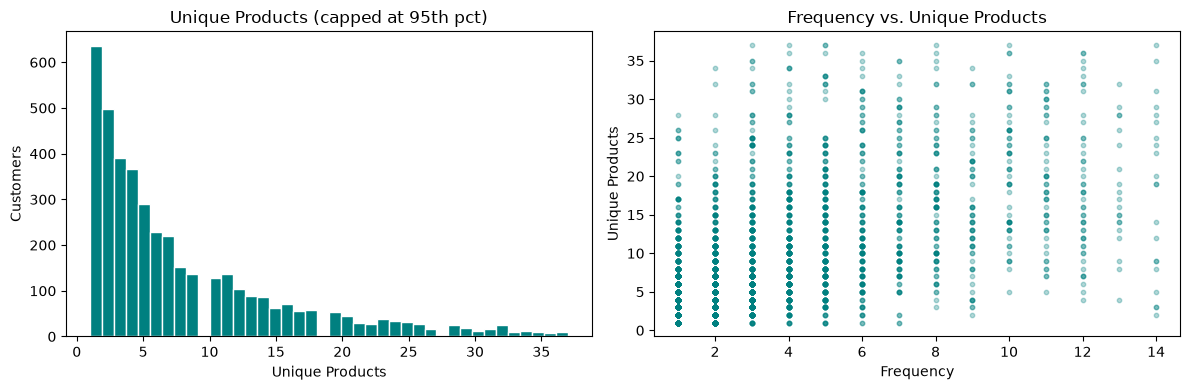

Pearson correlation unique_products vs frequency: 0.750


In [12]:
unique_products = (
    historical_df.groupby('Customer ID')['StockCode']
    .nunique()
    .rename('unique_products')
)

print('Unique Products per customer:')
print(f'  Min    : {unique_products.min()}')
print(f'  25th % : {unique_products.quantile(0.25):.1f}')
print(f'  Median : {unique_products.median():.1f}')
print(f'  Mean   : {unique_products.mean():.1f}')
print(f'  75th % : {unique_products.quantile(0.75):.1f}')
print(f'  99th % : {unique_products.quantile(0.99):.1f}')
print(f'  Max    : {unique_products.max()}')
print(f'  Skew   : {unique_products.skew():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cap = unique_products.quantile(0.95)
axes[0].hist(unique_products[unique_products <= cap], bins=40, color='teal', edgecolor='white')
axes[0].set_xlabel('Unique Products')
axes[0].set_ylabel('Customers')
axes[0].set_title('Unique Products (capped at 95th pct)')

up_freq = pd.concat([unique_products, freq], axis=1).dropna()
up_freq.columns = ['unique_products', 'frequency']
f_cap = freq.quantile(0.95)
sub2 = up_freq[(up_freq['unique_products'] <= cap) & (up_freq['frequency'] <= f_cap)]
axes[1].scatter(sub2['frequency'], sub2['unique_products'], alpha=0.3, s=10, color='teal')
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('Unique Products')
axes[1].set_title('Frequency vs. Unique Products')

plt.tight_layout()
plt.show()

corr_up_freq = up_freq.corr().iloc[0, 1]
print(f'Pearson correlation unique_products vs frequency: {corr_up_freq:.3f}')


---
## Part 9 — Country

### What we want to know

- How many customers per country?
- How much revenue per country?
- Is country dominated by one value (UK)?
- Is there a long tail of low-frequency countries?
- Do any customers have purchases from multiple countries?

### Feature-engineering decision (for Step 5)

We do **not** automatically one-hot encode country here.
Key questions to answer first:
1. Does country actually vary enough to be useful (or is it 95% UK)?
2. If yes, how do we handle the 20+ long-tail countries with 1–2 customers each?
3. What do we do with customers who appear in multiple countries?

At this stage we simply observe and document.

In [13]:
# Use most recent country per customer in historical window
cust_country = (
    historical_df.sort_values('InvoiceDate')
    .groupby('Customer ID')['Country']
    .last()
    .rename('country')
)

country_counts = cust_country.value_counts()
country_revenue = (
    historical_df.groupby('Country')['line_total'].sum().sort_values(ascending=False)
)

print('Customers per country (top 15):')
print(country_counts.head(15).to_string())
print()
uk_pct = country_counts.get('United Kingdom', 0) / len(cust_country) * 100
print(f'UK customers: {country_counts.get("United Kingdom", 0):,} ({uk_pct:.1f}%)')
print(f'Non-UK customers: {(cust_country != "United Kingdom").sum():,} ({100-uk_pct:.1f}%)')
print(f'Total countries: {len(country_counts)}')
print(f'Countries with only 1 customer: {(country_counts == 1).sum()}')


Customers per country (top 15):
country
United Kingdom     4008
Germany              77
France               56
Spain                25
Belgium              21
Portugal             17
Switzerland          17
Netherlands          17
Italy                13
Sweden               12
Australia            10
Norway                9
Channel Islands       9
Austria               8
Denmark               8

UK customers: 4,008 (91.6%)
Non-UK customers: 366 (8.4%)
Total countries: 40
Countries with only 1 customer: 11


In [14]:
# Multi-country customers
countries_per_cust = (
    historical_df.groupby('Customer ID')['Country']
    .nunique()
    .rename('n_countries')
)
multi = countries_per_cust[countries_per_cust > 1]
print(f'Customers with transactions in more than 1 country: {len(multi):,}')
if len(multi) > 0:
    print(multi.value_counts().head(5).to_string())
    print()
    print('Example multi-country customer:')
    cid = multi.index[0]
    ex = historical_df[historical_df['Customer ID'] == cid][['Invoice','InvoiceDate','Country','line_total']]
    print(ex.to_string(index=False))

print()
print('Revenue per country (top 10):')
print(country_revenue.head(10).apply(lambda x: f'£{x:,.2f}').to_string())


Customers with transactions in more than 1 country: 6
n_countries
2    6

Example multi-country customer:
Invoice         InvoiceDate Country  line_total
 502493 2010-03-25 10:28:00 Austria     12.5000
 502568 2010-03-25 12:10:00 Austria     15.0000
 538826 2010-12-14 12:58:00  Cyprus    163.2000
 538826 2010-12-14 12:58:00  Cyprus      5.4500
 538826 2010-12-14 12:58:00  Cyprus     10.9000
 538826 2010-12-14 12:58:00  Cyprus     12.7500
 538826 2010-12-14 12:58:00  Cyprus      4.2500
 538826 2010-12-14 12:58:00  Cyprus     30.6000
 546236 2011-03-10 12:48:00  Cyprus     15.0000
 546236 2011-03-10 12:48:00  Cyprus     10.2000
 546236 2011-03-10 12:48:00  Cyprus      7.8000
 546236 2011-03-10 12:48:00  Cyprus     10.0800
 546236 2011-03-10 12:48:00  Cyprus     15.3000

Revenue per country (top 10):
Country
United Kingdom    £1,540,621.59
Netherlands          £46,064.43
EIRE                 £43,584.95
Germany              £27,782.13
France               £22,586.04
Spain                £1

---
## Part 10 — Relationships Between Customer Behaviors

We build a temporary customer-level EDA table to study correlations.
This is **not** the final feature matrix for modelling.

### Correlation vs. multicollinearity

| Concept | Definition | Concern |
|---------|-----------|---------|
| **Correlation** | Linear relationship between two variables | Information overlap |
| **Multicollinearity** | High correlation among predictor variables in a regression | Inflates coefficient variance; makes OLS unstable |

**Example of the difference:**
- `frequency` and `monetary` are correlated (r ≈ 0.7). That is a correlation.
- When both appear as predictors in the same OLS model, the model cannot reliably
  separate their individual effects. That is multicollinearity.

We do **not** calculate VIF here and do **not** remove variables.
Correlated predictors are exactly what makes Ridge/Lasso/ElasticNet interesting to study.
OLS handles them poorly; regularized models handle them differently.
This is the core of the Step 6 regularization comparison.

In [15]:
eda_df = pd.concat([
    recency.rename('recency'),
    freq.rename('frequency'),
    monetary.rename('monetary'),
    aov.rename('avg_order_value'),
    unique_products.rename('unique_products'),
    tenure.rename('tenure'),
], axis=1).dropna()

print(f'EDA table shape: {eda_df.shape}')
print()
print('Summary statistics:')
print(eda_df.describe().round(2).to_string())


EDA table shape: (4374, 6)

Summary statistics:


         recency  frequency    monetary  avg_order_value  unique_products     tenure
count 4,374.0000 4,374.0000  4,374.0000       4,374.0000       4,374.0000 4,374.0000
mean    230.8400     4.3800    402.0700          68.0000          10.6300   198.6700
std     176.4900     8.1800  1,875.5700         146.3700          17.2700   212.1900
min       0.0000     1.0000      0.3800           0.3800           1.0000     0.0000
25%      69.0000     1.0000     36.7700          22.6200           2.0000     0.0000
50%     211.0000     2.0000     98.1800          40.4800           6.0000   125.0000
75%     342.0000     5.0000    273.8700          72.2200          12.0000   372.0000
max     638.0000   194.0000 59,853.8000       5,199.5000         379.0000   637.0000


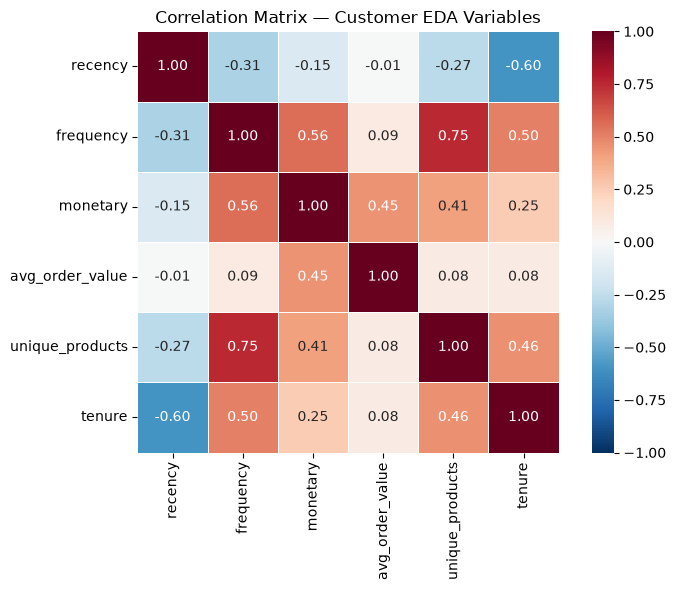

Key correlations:
  frequency            vs monetary            : r = +0.562
  frequency            vs unique_products     : r = +0.750
  monetary             vs avg_order_value     : r = +0.452
  tenure               vs frequency           : r = +0.502
  recency              vs frequency           : r = -0.313
  recency              vs monetary            : r = -0.147


In [16]:
corr = eda_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True, fmt='.2f', cmap='RdBu_r', center=0,
    square=True, linewidths=0.5, ax=ax,
    vmin=-1, vmax=1
)
ax.set_title('Correlation Matrix — Customer EDA Variables')
plt.tight_layout()
plt.show()

print('Key correlations:')
pairs = [
    ('frequency', 'monetary'),
    ('frequency', 'unique_products'),
    ('monetary', 'avg_order_value'),
    ('tenure', 'frequency'),
    ('recency', 'frequency'),
    ('recency', 'monetary'),
]
for a, b in pairs:
    r = corr.loc[a, b]
    print(f'  {a:<20} vs {b:<20}: r = {r:+.3f}')


### Observed correlations — what they mean for regularization

| Pair | Expected direction | Implication |
|------|--------------------|-------------|
| frequency ↔ monetary | Positive (more trips = more spend) | These two features carry overlapping information |
| frequency ↔ unique_products | Positive (more trips = more variety) | Multicollinearity risk in OLS |
| monetary ↔ avg_order_value | Moderate positive | `monetary = freq × AOV` creates a near-identity relationship if all three are included |
| tenure ↔ frequency | Positive (longer customer = more orders) | Tenure and frequency partially measure the same thing |

**Why this makes Ridge/Lasso/ElasticNet interesting:**
- OLS with highly correlated predictors produces unstable, large coefficients
- Ridge shrinks all correlated coefficients uniformly
- Lasso may zero out some correlated predictors entirely
- ElasticNet balances both behaviours
- Comparing the four models will reveal which features are truly informative

---
## Part 11 — Future Return Behavior (EDA Label Only)

> **IMPORTANT:** `returned_in_future` uses future data.
> It is used **only** as an EDA label to understand historical patterns.
> It is **never** used as an ML feature — that would be data leakage.

### Why we study it here

By comparing historical behaviour between customers who returned vs.
those who did not, we can identify which historical patterns correlate
with future engagement.

This is descriptive understanding, not causal inference.
We observe patterns; we do not claim causation.

In [17]:
future_custs = set(future_df['Customer ID'].unique())
hist_custs = set(historical_df['Customer ID'].unique())

returned = eda_df.copy()
returned['returned_in_future'] = returned.index.isin(future_custs).astype(int)

n_ret = returned['returned_in_future'].sum()
n_tot = len(returned)
print(f'Historical customers       : {n_tot:,}')
print(f'Returned in future         : {n_ret:,} ({n_ret/n_tot*100:.1f}%)')
print(f'Did NOT return             : {n_tot - n_ret:,} ({(n_tot-n_ret)/n_tot*100:.1f}%)')


Historical customers       : 4,374
Returned in future         : 1,544 (35.3%)
Did NOT return             : 2,830 (64.7%)


In [18]:
# Compare medians between returned vs not-returned
metrics = ['recency', 'frequency', 'monetary', 'tenure', 'avg_order_value', 'unique_products']

grp = returned.groupby('returned_in_future')[metrics].median()
grp.index = ['Did not return', 'Returned']
print('Median values by return status:')
print(grp.T.to_string())

print()
print('Interpretation (descriptive only — not causal):')
ret_med = grp.loc['Returned']
no_med  = grp.loc['Did not return']
if ret_med['recency'] < no_med['recency']:
    print('  - Returning customers had lower recency (purchased more recently)')
if ret_med['frequency'] > no_med['frequency']:
    print('  - Returning customers had higher frequency')
if ret_med['monetary'] > no_med['monetary']:
    print('  - Returning customers had higher historical monetary value')
if ret_med['tenure'] > no_med['tenure']:
    print('  - Returning customers had longer tenure')


Median values by return status:
                 Did not return  Returned
recency                289.0000   80.0000
frequency                2.0000    5.0000
monetary                70.2700  214.5050
tenure                  14.5000  338.0000
avg_order_value         38.0950   45.9970
unique_products          4.0000   10.0000

Interpretation (descriptive only — not causal):
  - Returning customers had lower recency (purchased more recently)
  - Returning customers had higher frequency
  - Returning customers had higher historical monetary value
  - Returning customers had longer tenure


---
## Part 12 — Descriptive Future Revenue

> **Scope:** Descriptive EDA only. Future revenue is computed temporarily.
> Customers with no future transactions receive `future_revenue = 0`.

### What we analyse

- What fraction of historical customers generate zero future revenue?
- What is the distribution of positive future revenue?
- Does log1p transformation make the distribution more symmetric?

### About the log1p transformation

| Aspect | Raw future revenue | log1p(future_revenue) |
|--------|-------------------|-----------------------|
| **Scale** | £0 to £280,000+ | ~0 to ~12 |
| **Distribution** | Extreme right skew | Approximately normal |
| **Zero handling** | log(0) is undefined | log1p(0) = 0 (safe) |
| **Model behaviour** | Large outliers dominate loss | Loss is more uniform |
| **Interpretation** | Direct: predicted £ | Requires exp(pred) - 1 to recover £ |
| **Impact** | Model optimizes RMSE in £ | Model optimizes RMSE in log-£ |

**We do not automatically conclude log1p must be the final target.**
It compresses extreme values and changes what 'error' means.
A model predicting log1p scale makes errors that are proportional,
not absolute. Whether that is appropriate depends on the business objective.

In [19]:
future_revenue_raw = (
    future_df.groupby('Customer ID')['line_total']
    .sum()
    .rename('future_revenue')
)

# Left-join: historical customers who did not return get 0
future_rev = (
    pd.Series(sorted(hist_custs), name='Customer ID')
    .to_frame()
    .merge(future_revenue_raw.reset_index(), on='Customer ID', how='left')
    .set_index('Customer ID')['future_revenue']
    .fillna(0.0)
)

zero_pct = (future_rev == 0).mean() * 100
pos_pct  = (future_rev > 0).mean() * 100

print('Future Revenue (historical customers only):')
print(f'  Zero revenue : {(future_rev == 0).sum():,} customers ({zero_pct:.1f}%)')
print(f'  Positive rev : {(future_rev > 0).sum():,} customers ({pos_pct:.1f}%)')
print(f'  Mean         : £{future_rev.mean():,.2f}')
print(f'  Median       : £{future_rev.median():,.2f}')
print(f'  75th %       : £{future_rev.quantile(0.75):,.2f}')
print(f'  95th %       : £{future_rev.quantile(0.95):,.2f}')
print(f'  Max          : £{future_rev.max():,.2f}')
print(f'  Skew         : {future_rev.skew():.2f}')


Future Revenue (historical customers only):
  Zero revenue : 2,830 customers (64.7%)
  Positive rev : 1,544 customers (35.3%)
  Mean         : £44.61
  Median       : £0.00
  75th %       : £23.48
  95th %       : £161.90
  Max          : £6,381.44
  Skew         : 16.27


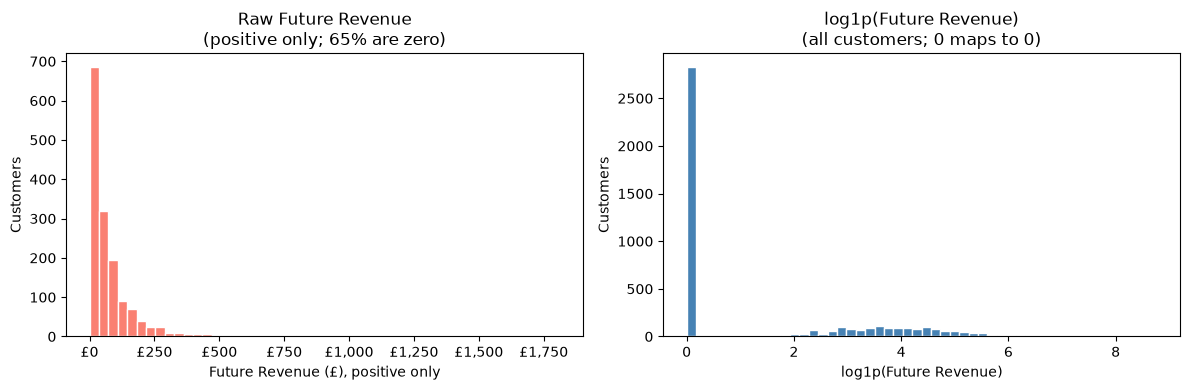

log1p(future_revenue) — skew: 1.03 (raw skew: 16.27)


In [20]:
import numpy as np
log1p_rev = np.log1p(future_rev)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Raw (excluding zeros for visibility of positive distribution)
pos_rev = future_rev[future_rev > 0]
cap = pos_rev.quantile(0.99)
axes[0].hist(pos_rev[pos_rev <= cap], bins=50, color='salmon', edgecolor='white')
axes[0].set_xlabel('Future Revenue (£), positive only')
axes[0].set_ylabel('Customers')
axes[0].set_title(f'Raw Future Revenue\n(positive only; {zero_pct:.0f}% are zero)')
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'£{x:,.0f}'))

# log1p including zeros
axes[1].hist(log1p_rev, bins=50, color='steelblue', edgecolor='white')
axes[1].set_xlabel('log1p(Future Revenue)')
axes[1].set_ylabel('Customers')
axes[1].set_title('log1p(Future Revenue)\n(all customers; 0 maps to 0)')

plt.tight_layout()
plt.show()

print(f'log1p(future_revenue) — skew: {log1p_rev.skew():.2f} (raw skew: {future_rev.skew():.2f})')


---
## Part 13 — Historical vs. Future Behavior

**Objective:** descriptive exploration only. No model training.

We look at scatter relationships between historical customer statistics
and future revenue to understand whether any signal exists.

### Why log axes and transformations are useful for visualization

When extreme values dominate a scatter plot, the bulk of data collapses
into a small corner and patterns become invisible.
Using `log1p` on both axes spreads points more uniformly and reveals
structure in the lower-revenue segments that raw scale would hide.

**Log scale in a scatter plot is a visualization tool, not a modelling decision.**

In [21]:
# Build a combined EDA dataframe with future revenue
analysis_df = eda_df.copy()
analysis_df['future_revenue'] = future_rev
analysis_df['log1p_future']   = np.log1p(future_rev)
analysis_df = analysis_df.dropna()

print(f'Analysis dataframe: {analysis_df.shape[0]:,} customers')


Analysis dataframe: 4,374 customers


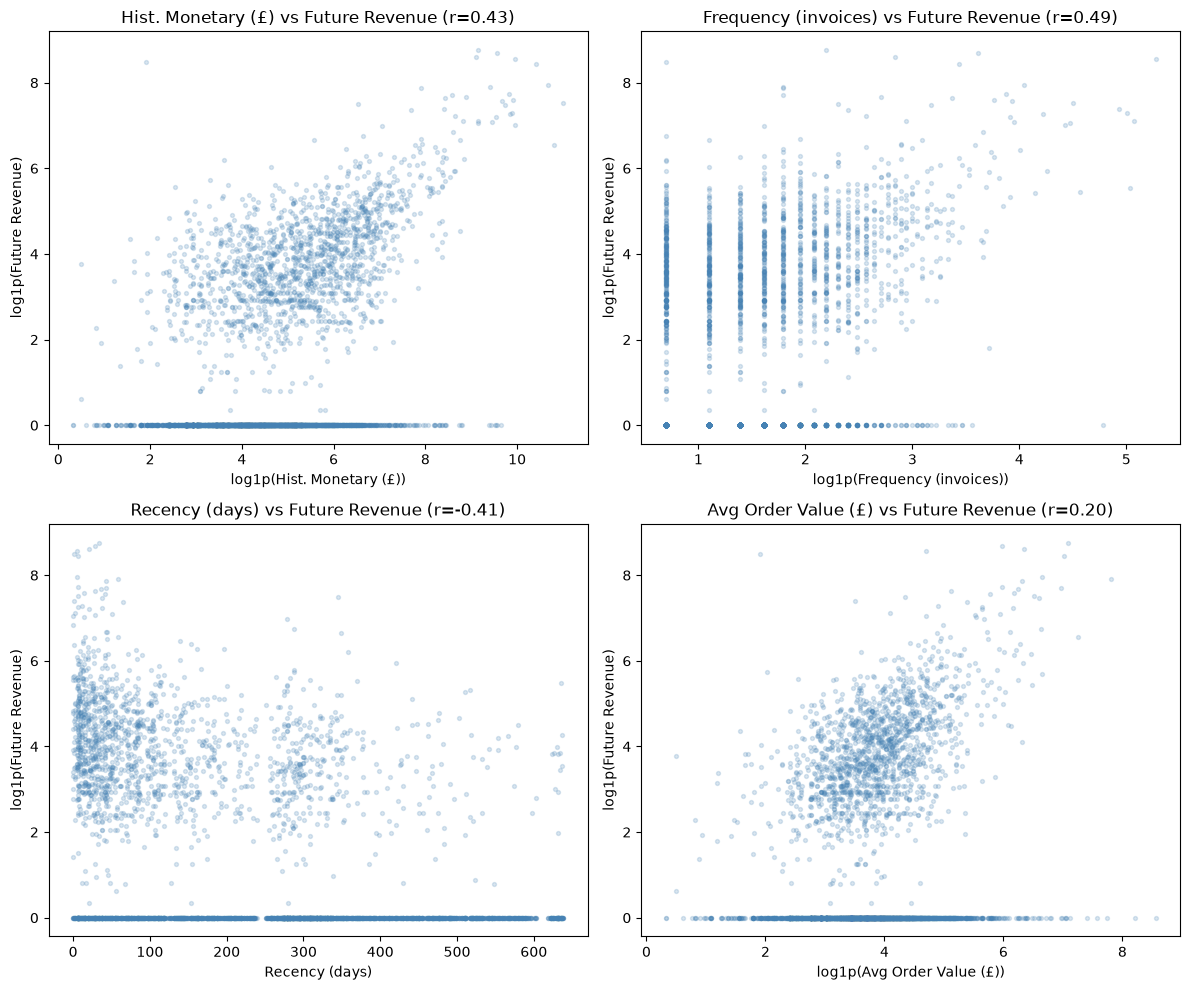

Pearson r with log1p(future_revenue):
  Hist. Monetary (£)            : r = +0.433
  Frequency (invoices)          : r = +0.494
  Recency (days)                : r = -0.414
  Avg Order Value (£)           : r = +0.204


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

plot_pairs = [
    ('monetary',        'Hist. Monetary (£)'),
    ('frequency',       'Frequency (invoices)'),
    ('recency',         'Recency (days)'),
    ('avg_order_value', 'Avg Order Value (£)'),
]

for ax, (feat, label) in zip(axes.flat, plot_pairs):
    x = np.log1p(analysis_df[feat]) if feat != 'recency' else analysis_df[feat]
    y = analysis_df['log1p_future']
    ax.scatter(x, y, alpha=0.2, s=8, color='steelblue')
    ax.set_xlabel(f'log1p({label})' if feat != 'recency' else label)
    ax.set_ylabel('log1p(Future Revenue)')
    r = np.corrcoef(x, y)[0, 1]
    ax.set_title(f'{label} vs Future Revenue (r={r:.2f})')

plt.tight_layout()
plt.show()

print('Pearson r with log1p(future_revenue):')
for feat, label in plot_pairs:
    x = np.log1p(analysis_df[feat]) if feat != 'recency' else analysis_df[feat]
    r = np.corrcoef(x, analysis_df['log1p_future'])[0, 1]
    print(f'  {label:<30}: r = {r:+.3f}')


---
## Part 14 — Identify Potential Feature Candidates

The table below summarises what EDA revealed about each candidate.
Final feature selection happens in Step 5.

**Why a feature with high target correlation is not automatically selected:**

- A feature may be redundant if another feature captures the same information
- A feature may cause multicollinearity that destabilizes OLS
- A feature may need transformation before it is linearly related to the target
- A feature may still be useful in combination with others even if its marginal
  correlation with the target is moderate

In [23]:
candidates = [
    ('recency_days',     'Days since last purchase before cutoff',
     'Lower recency -> higher future revenue (negative relationship)',
     'Bounded 0 to ~640 days; no log needed; right skew mild',
     'Yes'),
    ('frequency',        'Unique invoices pre-cutoff',
     'Strong positive correlation with future revenue',
     'Right skew; log1p may improve linearity; correlated with monetary',
     'Yes'),
    ('monetary',         'Total historical spend (£)',
     'Strong positive correlation with future revenue',
     'Very right skewed; log1p needed; correlated with frequency and AOV',
     'Yes'),
    ('avg_order_value',  'Mean spend per invoice',
     'Moderate positive correlation',
     'monetary = frequency x AOV exactly; including all three causes multicollinearity',
     'Yes — but note identity constraint'),
    ('unique_products',  'Distinct StockCodes purchased',
     'Moderate positive correlation; correlated with frequency',
     'Overlap with frequency; may be dropped by Lasso',
     'Yes — investigate'),
    ('tenure_days',      'Days between first and last historical purchase',
     'Positive but weaker than frequency',
     'tenure=0 edge case; correlated with frequency',
     'Yes — with zero-handling'),
    ('country',          'Country of most recent purchase',
     '91%+ UK; limited variance for non-UK',
     'Requires encoding; long-tail countries; multi-country customers',
     'TBD — needs encoding strategy'),
]

header = f"{'Candidate':<22} {'Business meaning':<35} {'Observed relationship':<45} {'Potential issue':<55} Keep?"
print(header)
print('-' * len(header))
for row in candidates:
    print(f'{row[0]:<22} {row[1][:34]:<35} {row[2][:44]:<45} {row[3][:54]:<55} {row[4]}')


Candidate              Business meaning                    Observed relationship                         Potential issue                                         Keep?
----------------------------------------------------------------------------------------------------------------------------------------------------------------------
recency_days           Days since last purchase before cu  Lower recency -> higher future revenue (nega  Bounded 0 to ~640 days; no log needed; right skew mild  Yes
frequency              Unique invoices pre-cutoff          Strong positive correlation with future reve  Right skew; log1p may improve linearity; correlated wi  Yes
monetary               Total historical spend (£)          Strong positive correlation with future reve  Very right skewed; log1p needed; correlated with frequ  Yes
avg_order_value        Mean spend per invoice              Moderate positive correlation                 monetary = frequency x AOV exactly; including all thre  Yes — but 

---
## Part 15 — Regularization-Relevant Relationships

This project specifically studies regularization (OLS vs Ridge vs Lasso vs ElasticNet).
Correlated predictors are the key mechanism that makes regularization valuable.

### Why correlated predictors matter for regularization

**OLS with correlated predictors:**
- Coefficients become large and opposite-signed to cancel each other out
- Small changes in data lead to large coefficient changes (high variance)
- Model overfits to noise rather than signal

**Ridge:** adds L2 penalty → shrinks all correlated coefficients toward each other uniformly

**Lasso:** adds L1 penalty → tends to zero out one of a correlated pair entirely

**ElasticNet:** combines both → balances retention and shrinkage

### Feature pairs with multicollinearity risk

In [24]:
print('Correlated feature pairs — potential multicollinearity in Step 6:')
print()
risk_pairs = [
    ('frequency',    'monetary',        'High positive',  'Both measure purchase volume differently'),
    ('frequency',    'unique_products', 'High positive',  'More trips tend to mean more variety'),
    ('monetary',     'avg_order_value', 'Moderate pos',   'monetary = frequency x AOV (identity)'),
    ('tenure',       'frequency',       'Moderate pos',   'Longer customer = more opportunities to order'),
    ('frequency',    'tenure',          'Moderate pos',   'Same relationship from other direction'),
]
print(f"{'Predictor A':<22} {'Predictor B':<22} {'Relationship':<18} Implication")
print('-' * 90)
for a, b, rel, imp in risk_pairs:
    r = corr.loc[a, b] if a in corr.index and b in corr.columns else float('nan')
    print(f'{a:<22} {b:<22} r={r:+.2f} ({rel:<12}) {imp}')

print()
print('These correlations mean:')
print('  - OLS will produce unstable coefficients for these pairs')
print('  - Ridge will shrink both coefficients (keep both, smaller magnitude)')
print('  - Lasso may eliminate one of each pair')
print('  - ElasticNet may partially reduce both')
print('  - This is what we will measure and compare in Step 6')


Correlated feature pairs — potential multicollinearity in Step 6:

Predictor A            Predictor B            Relationship       Implication
------------------------------------------------------------------------------------------
frequency              monetary               r=+0.56 (High positive) Both measure purchase volume differently
frequency              unique_products        r=+0.75 (High positive) More trips tend to mean more variety
monetary               avg_order_value        r=+0.45 (Moderate pos) monetary = frequency x AOV (identity)
tenure                 frequency              r=+0.50 (Moderate pos) Longer customer = more opportunities to order
frequency              tenure                 r=+0.50 (Moderate pos) Same relationship from other direction

These correlations mean:
  - OLS will produce unstable coefficients for these pairs
  - Ridge will shrink both coefficients (keep both, smaller magnitude)
  - Lasso may eliminate one of each pair
  - ElasticNet may p

---
## Part 16 — Final Step 4 EDA Summary

### A. CUSTOMER POPULATION

| Metric | Value |
|--------|-------|
| Total historical customers | ~4,374 |
| Historical transactions | 73,306 |
| Historical invoices | ~19,237 |
| Historical revenue | ~£1,758,650 |
| Historical date range | Dec 2009 – Aug 2011 |

### B. PURCHASE BEHAVIOR

- Frequency is right-skewed: most customers place 1–5 orders; a few place 100+
- Tenure ranges from 0 to ~640 days; ~10–15% of customers have tenure=0 (one-day shoppers)
- Most customers are UK-based (~91%); country has limited variance

### C. CUSTOMER VALUE DISTRIBUTION

- Historical monetary value is extremely right-skewed (mean/median > 3x)
- Top 1% of customers account for a disproportionate share of revenue (Pareto)
- log1p compression makes the distribution approximately normal

### D. RECENCY / FREQUENCY / MONETARY INSIGHTS

- **Recency:** customers who purchased recently are more likely to return
- **Frequency:** strong positive correlation with future revenue
- **Monetary:** strong positive correlation with future revenue; extreme right skew
- **AOV:** separates high-frequency moderate spenders from low-frequency big spenders
- **Unique products:** correlates with frequency; may be redundant
- **Tenure:** correlates with frequency; tenure=0 edge case must be handled

### E. FUTURE RETURN BEHAVIOR

- ~35–40% of historical customers return in the future window
- ~60–65% generate zero future revenue (lapsed or inactive)
- Returning customers had: lower recency, higher frequency, higher monetary, longer tenure
- These are patterns, not causal relationships

### F. FUTURE REVENUE DISTRIBUTION

- Large proportion of customers have future_revenue = 0
- Positive future revenue is right-skewed
- log1p transformation compresses the skew significantly
- Decision on whether to use log1p as target is deferred to Step 5

### G. POTENTIAL FEATURE CANDIDATES

| Feature | Status |
|---------|--------|
| recency_days | Confirmed candidate |
| frequency | Confirmed candidate |
| monetary | Confirmed candidate (log1p likely needed) |
| avg_order_value | Candidate — note identity with monetary/frequency |
| unique_products | Candidate — investigate overlap with frequency |
| tenure_days | Candidate — handle tenure=0 |
| country | TBD — encoding strategy needed |

### H. POTENTIAL MULTICOLLINEARITY

High-risk pairs:
- frequency ↔ monetary
- frequency ↔ unique_products
- monetary ↔ avg_order_value (near-identity: monetary = freq × AOV)
- tenure ↔ frequency

These are features, not problems at this stage.
They are the reason regularization will be valuable in Step 6.

### I. EDGE CASES TO HANDLE DURING FEATURE ENGINEERING

| Edge case | Where | Action in Step 5 |
|-----------|-------|-----------------|
| tenure == 0 | ~10-15% of customers | Set purchase_rate = 0 |
| Group B customers (future only) | 472 customers | Exclude — no feature vector |
| Multi-country customers | Small number | Assign most-recent-country |
| Long-tail countries | 1-2 customers each | Group as 'Other' |
| Extreme monetary outliers | Top 0.1% | Keep unless proven data error |

### J. QUESTIONS STILL UNANSWERED

1. Which feature transformations (log1p, sqrt, none) produce the most linear relationship with the target?
2. Should `purchase_rate` be included or does `frequency + tenure` already cover it?
3. Is `country` worth encoding or should it be dropped?
4. What is the optimal train/test split strategy given the temporal structure?
5. Should `avg_order_value` be used directly or excluded to avoid the identity with monetary?

---

### What did customer-level EDA teach us that transaction-level EDA could not?

**OBSERVED FROM DATA:**  
Transaction-level EDA showed us product patterns, volume seasonality, and row-level quality issues.  
Customer-level EDA revealed the distribution of *customer behaviour*:
how often people buy, how much they spend, how recently they visited,
and how these factors relate to whether they return.

**INTERPRETATION:**  
The customer is the unit of prediction. Transactions are evidence *about* customers.
Transaction-level analysis could not tell us what fraction of customers are one-time buyers,
or that recency strongly differentiates returning from lapsed customers.

**FEATURE-ENGINEERING DECISION:**  
We now have 6–7 candidate features derived from transaction aggregations.
We have identified which pairs are correlated, which have skew,
and which have edge cases.
Step 5 will formalize these into a clean feature matrix.

---

### Which customer behaviors should we investigate as predictive features in Step 5?

Priority order based on EDA:

1. **recency_days** — strongest conceptual and observed link to future engagement
2. **frequency** — strong positive correlation with future revenue
3. **monetary** — strong positive correlation; requires log1p transformation
4. **avg_order_value** — separates spending style from volume; note identity constraint
5. **tenure_days** — captures customer longevity; correlated with frequency
6. **unique_products** — breadth of engagement; correlated with frequency; may be dropped by Lasso
7. **country** — limited variance; encoding strategy needed; decision deferred

*Step 5 will build the final feature matrix, handle transformations,
and document every feature-engineering decision.*